# How to create a custom model

**Author**: Malte Lüken (m.luken@esciencecenter.nl)

**Difficulty**: Intermediate

This tutorial explains how to create a custom model with prfmodel.

## Part 1: Implementing a 1D Gaussian pRF model

In the first part, I show how to implement a 1-dimensional Gaussian population receptive field (pRF) model analogous
to the existing 2-dimensional model. The 1D model is often used to model neural responses to auditory or numerosity
stimuli that lie on a single dimension (i.e., tone frequency or the displayed integer number).

Because prfmodel uses Keras for model fitting, we need to make sure that a backend is installed before we begin.
In this tutorial, we use the TensorFlow backend.

In [2]:
import os
from importlib.util import find_spec

os.environ["KERAS_BACKEND"] = "tensorflow"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "1"

if find_spec("tensorflow") is None:
    msg = "Could not find the tensorflow package. Please install tensorflow with 'pip install .[tensorflow]'"
    raise ImportError(msg)

### Creating a 1D stimulus

We start by creating a 1D {py:class}`~prfmodel.stimuli.PRFStimulus`. In this example, we simulate a numerosity stimulus where different quantities of objects are consecutively presented on a screen. At each time frame, a different quantity (numerosity) is presented.

The numerosity dimension is represented as a 1D grid, and the stimulus design is a binary matrix indicating which numerosity is active at each time frame. We repeat each numerosity for two consecutive frames and repeat all numerosities 10 times. Instead of the raw numerosity
integers, we use the log of the integers as the stimulus grid. This means that the pRF model will also receive the log numerosity as input and it's parameters will live in the log numerosity space.

In [3]:
import numpy as np
from prfmodel.stimuli import PRFStimulus

num_frames = 160
unique_numerosities = np.array([1, 2, 3, 4, 5, 6, 7, 20])
unique_log_numerosities = np.log(unique_numerosities)
num_numerosities = unique_numerosities.shape[0]

# Create a 1D grid with unique log numerosities
grid = np.expand_dims(unique_log_numerosities, 1)  # shape (num_numerosities, 1)

# Create the design containing one-hot encoded numerosities displayed at each time frame
design = np.zeros((num_frames, num_numerosities))

num_cycles = 10

frame = 0

for cycle in range(num_cycles):
    for cycle_frame in range(num_frames // num_cycles):
        numerosity_idx = cycle_frame // 2
        # Insert a binary indicator for which numerosity is active
        design[frame, numerosity_idx] = 1
        frame += 1

We can visualize the design matrix with the displayed numerosity at each time frame on the natural and log scale.

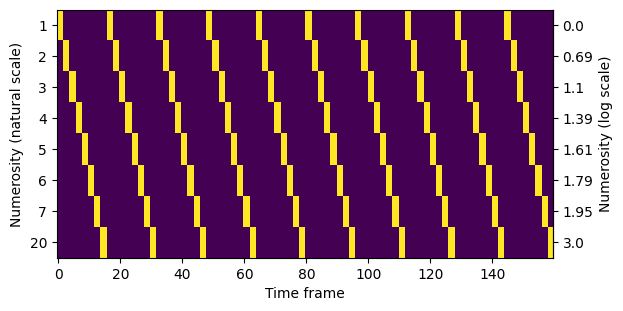

In [4]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots()

ax.imshow(design.T, aspect=num_frames/16)
ax.set_xlabel("Time frame")
ax.set_ylabel("Numerosity (natural scale)")
ax.set_yticks(np.arange(len(unique_numerosities)))
ax.set_yticklabels(unique_numerosities)

secax = ax.secondary_yaxis("right")
secax.set_ylabel("Numerosity (log scale)")
secax.set_yticks(np.arange(len(unique_numerosities)))
secax.set_yticklabels(np.round(unique_log_numerosities, 2));

We can create a `PRFStimulus` object with the `design` and `grid`.

In [5]:
stimulus = PRFStimulus(design=design, grid=grid, dimension_labels=["log_numerosity"])
print(stimulus)

PRFStimulus(design=array[160, 8], grid=array[8, 1], dimension_labels=['log_numerosity'])


### Implementing the custom response model

Now we implement the 1D Gaussian response class by subclassing {py:class}`~prfmodel.models.base.BaseResponse`. We first
take a look at the docstring of the class:

In [7]:
from prfmodel.models.base import BasePopulationResponse

help(BasePopulationResponse)

Help on class BasePopulationResponse in module prfmodel.models.base:

class BasePopulationResponse(prfmodel.utils.ModelProtocol, typing.Generic)
 |  BasePopulationResponse(*args, **kwargs)
 |
 |  Generic abstract base class for neuron population response models.
 |
 |  A neuron population response model takes a stimulus and parameters as input and predicts a population response.
 |
 |  Notes
 |  -----
 |  This class cannot be instantiated on its own. It can only be used as a parent class to create custom response
 |  models. Subclasses must override the abstract :attr:`parameter_names` and :meth:`__call__` method.
 |  They must be defined with a specific stimulus type. See :mod:`~prfmodel.models.base` for details.
 |
 |  Examples
 |  --------
 |  Reimplement a 2D isotropic Gaussian response model for a :class:`~prfmodel.stimuli.PRFStimulus`.
 |
 |  >>> import pandas as pd
 |  >>> from prfmodel.examples import load_2d_prf_bar_stimulus
 |  >>> from prfmodel.stimuli import PRFStimulus
 | 

We can see that `BaseResponse` has two abstract methods that must be overridden when subclassing:

```
__abstractmethods__ = frozenset({'__call__', 'parameter_names'}).
```

1. The `parameter_names` property, which lists the parameter names the model expects.
2. The `__call__` method, which computes the pRF response for a given stimulus and parameter set. This method can implement an arbitrary response function, but here we re-use {py:fun}`~prfmodel.models.prf.gaussian.predict_gaussian_response` from the Gaussian module, which is dimension-agnostic and works for any number of spatial dimensions.

We can also see that `BaseResponse` is a generic class with respect to the `stimulus` argument in the `__call__` method.
This means we need to specify for which stimulus type the class is defined. In our case, this is the {py:class}`~prfmodel.stimuli.PRFStimulus` class
(for a connective field response model, this would be {py:class}`~prfmodel.stimuli.CFStimulus`).

In [8]:
import pandas as pd
from keras import ops

from prfmodel.models.prf import predict_gaussian_response
from prfmodel.stimuli import PRFStimulus
from prfmodel.utils import convert_parameters_to_tensor, get_dtype

# Define the generic class for the concrete 'PRFStimulus' type
class Gaussian1DPRFResponse(BasePopulationResponse[PRFStimulus]):
    # 'parameter_names' is a property so that it becomes "immutable"
    @property
    def parameter_names(self) -> list[str]:
        """Names of parameters used by the model: `mu_x`, `sigma`."""
        return ["mu_x", "sigma"]

    def __call__(
            self,
            # The 'stimulus' argument must be the same type as the concrete type above
            stimulus: PRFStimulus,
            parameters: pd.DataFrame,
            dtype: str | None = None
        ):
        """Predict the model response for a stimulus with a 1D grid.

        Parameters
        ----------
        stimulus : PRFStimulus
            Stimulus object.
        parameters : pandas.DataFrame
            Dataframe with columns containing different model parameters and rows containing parameter values
            for different units.
        dtype : str, optional
            The dtype of the prediction result. If `None` (the default), uses the dtype from
            :func:`prfmodel.utils.get_dtype`.

        Returns
        -------
        Tensor
            Model predictions of shape `(num_units, size_x)` and dtype `dtype`.
            `num_units` is the number of rows in `parameters` and `size_x` is the size of the
            stimulus grid dimension.

        """
        # Explicit dtypes avoid dtype mismatch errors
        dtype = get_dtype(dtype)
        mu = convert_parameters_to_tensor(parameters[["mu_x"]], dtype=dtype)
        sigma = convert_parameters_to_tensor(parameters[["sigma"]], dtype=dtype)
        # Explicit tensor conversion avoids type mismatch errors
        grid = ops.convert_to_tensor(stimulus.grid, dtype=dtype)
        # We can implement the Gaussian response from scratch
        # import math

        # grid = ops.expand_dims(grid, 0)
        # mu = ops.expand_dims(mu, 1)
        # sigma_squared = ops.square(sigma)

        # # Gaussian response
        # resp = ops.sum(ops.square(grid - mu), axis=-1)
        # resp /= 2 * sigma_squared

        # # Divide by volume to normalize
        # volume = (2 * math.pi * sigma_squared) ** (1 / 2)

        # return ops.exp(-resp) / volume

        # Or we can use an existing function to predict a Gaussian response
        return predict_gaussian_response(grid, mu, sigma)

The `mu_x` parameter defines the preferred location on the stimulus dimension (here: preferred log numerosity) and `sigma` defines the tuning width. Both `mu` and `sigma` are converted from the `parameters` DataFrame to tensors with shapes `(num_units, 1)`.

`predict_gaussian_response` expects `mu` and `sigma` to have at least two dimensions — the first for the number of units and the second for the number of spatial dimensions. The function then broadcasts these tensors against the stimulus `grid` to compute the Gaussian response for each unit.

### Creating the model

With the `Gaussian1DPRFResponse` class defined, we pass it as the `prf_model` argument to {py:class}`~prfmodel.models.canonical.CanonicalPRFModel`. The canonical model handles stimulus encoding, HRF convolution, and baseline amplitude scaling using default submodels.

In [9]:
from prfmodel.models.prf.canonical import CanonicalPRFModel

model = CanonicalPRFModel(
    prf_model=Gaussian1DPRFResponse(),
)

We can inspect all parameters required by the composite model through the `parameter_names` property.

In [10]:
model.parameter_names

['mu_x',
 'sigma',
 'delay',
 'dispersion',
 'undershoot',
 'u_dispersion',
 'ratio',
 'weight_deriv',
 'baseline',
 'amplitude']

The parameters `mu_x` and `sigma` come from our custom `Gaussian1DResponse`. The remaining parameters belong to the default impulse response model ({py:class}`~prfmodel.models.impulse.DerivativeTwoGammaImpulse`) and the scaling model ({py:class}`~prfmodel.models.temporal.BaselineAmplitude`).

### Simulating a neural response

Let's simulate predicted neural responses for each unique numerosity while keeping the tuning width fixed to `sigma = 1`.

In [16]:
num_units = len(unique_numerosities)

params_mu_x = pd.DataFrame(
    {
        "mu_x": unique_log_numerosities,  # We need to specify the location of the Gaussian in log space
        "sigma": [1.0] * num_units,  # We keep the tuning width fixed
        "delay": [6.0] * num_units,
        "dispersion": [0.9] * num_units,
        "undershoot": [12.0] * num_units,
        "u_dispersion": [0.9] * num_units,
        "ratio": [0.48] * num_units,
        "weight_deriv": [0.5] * num_units,
        "baseline": [0.0] * num_units,
        "amplitude": [1.0] * num_units,
    }
)

prediction = np.asarray(model(stimulus, params_mu_x))
print(prediction.shape)

(8, 160)


The output has shape `(8, num_frames)` -- one predicted time course for each unique numerosity.

We can visualize the predicted response over time.

In [18]:
import plotly.io as pio
import plotly.express as px

pio.renderers.default = "notebook_connected"  # Requires internet connection to work
pio.templates.default = "simple_white"

fig = px.line(
    prediction.T,
    animation_frame="variable",
    range_x=(0, num_frames),
    range_y=(-0.1, 0.6),
    labels={
        "index": "Time frame",
        "value": "Predicted neural response",
        "variable": "Numerosity (natural scale)",
    },
)
fig.update_layout(showlegend=False, height=450)
fig.show()

The predicted response peaks around the time frames at which the stimulus design passes through each units's preferred frequency, and decays afterwards due to the impulse response convolution. This is exactly what we would expect from a 1D Gaussian pRF model.

We can also simulate and visualize predicted timecourses for different tuning widths `sigma`.

In [13]:
num_units = 10

params_sigma = pd.DataFrame(
    {
        "mu_x": np.log([3] * num_units),
        "sigma": np.linspace(0.05, 3.0, num_units),
        "delay": [6.0] * num_units,
        "dispersion": [0.9] * num_units,
        "undershoot": [12.0] * num_units,
        "u_dispersion": [0.9] * num_units,
        "ratio": [0.48] * num_units,
        "weight_deriv": [0.5] * num_units,
        "baseline": [0.0] * num_units,
        "amplitude": [1.0] * num_units,
    }
)

prediction = np.asarray(model(stimulus, params_sigma))

fig = px.line(
    prediction.T,
    animation_frame="variable",
    range_x=(0, num_frames),
    range_y=(-2.0, 5.0),
    labels={
        "index": "Time frame",
        "value": "Predicted neural response",
        "variable": "pRF width (sigma)",
    },
)
fig.update_layout(showlegend=False, height=450)
fig.show()

We can see that the tuning width determines the sharpness of the predicted response peaks.

## Part 2: TBD

This part will be added in a future version.

## Conclusion

In this tutorial, I showed how to create a custom 1D Gaussian pRF model for a fictional numerosity experiment. I first created a stimulus for the fictional experiment. Then, I created a custom pRF response model and inserted it into the default composite pRF model
that combines the pRF response with an impulse and scaling model.

## References

Harvey, B. M., Klein, B. P., Petridou, N., & Dumoulin, S. O. (2013). Topographic representation of numerosity in the human parietal cortex. *Science*, *341*(6150), 1123-1126. https://doi.org/10.1126/science.1239052